# Etapa 2. Cola con prioridades (heap)

**Proyecto EDA 2026-2, Grupo 1, escenario B (comercio electrónico).**
Responsable de las etapas 0, 1 y 2: Cristina.

## Función de la etapa en el pipeline

La etapa 2 decide **en qué orden** se atienden los eventos limpios que entrega la etapa 1. El escenario B pide atender las órdenes express, estándar y programadas según su urgencia y dar la máxima prioridad a las alertas de pago o fraude. Cuando llegan más eventos de los que el sistema puede atender, los urgentes pasan primero y los demás esperan en una cola con prioridades.

La estructura es un **min-heap binario** implementado a mano. `heapq` y una lista ordenada se usan solo como líneas base.

## Proceso

```
lotes limpios (etapa 1)
   │
   ├─ 1. asignar clase de prioridad y deadline a cada evento
   ├─ 2. insertar en el min-heap con clave (clase, deadline, seq)       O(log n)
   ├─ 3. cada cierto tiempo, aging: subir de clase lo que espera mucho   O(n)
   └─ 4. extraer los eventos más prioritarios según la capacidad        O(log n) cada uno
   │
eventos en orden de servicio (etapas 3, 6 y 8)
```

## Pasos del notebook

1. Configuración y lectura de la salida de la etapa 1.
2. Clases de prioridad y deadlines.
3. Min-heap propio.
4. Cola de prioridades con aging.
5. Simulación del servicio con capacidad limitada.
6. Efecto del aging durante un incidente de capacidad.
7. Experimentos de complejidad.
8. Salida de la etapa 2.

## Paso 1. Configuración y entrada

La entrada es `data/interim/<CATEGORIA>/etapa1_lotes.jsonl`, generado por el notebook de la etapa 1. La categoría y las rutas se toman de `src/config.py`. Cada línea es un lote de eventos con el formato `Event`.

Los lotes se cargan completos en memoria porque la simulación del paso 6 los recorre tres veces, una por escenario, y todos los escenarios deben recibir exactamente los mismos datos. En el pipeline en línea la etapa recibiría cada lote directamente de la etapa 1. Esta carga completa es viable en modo desarrollo; con las 2 500 000 reseñas del experimento habría que procesar los lotes sin guardarlos todos.

In [1]:
import bisect                     # solo como línea base en los experimentos
import gc
import heapq                      # solo como línea base en los experimentos
import json
import platform
import random
import time
import tracemalloc
from collections import Counter
from dataclasses import dataclass, asdict
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil

# Raíz del proyecto: se sube de carpeta hasta encontrar la que contiene notebooks/ y data/
RAIZ = Path.cwd()
while not ((RAIZ / "notebooks").is_dir() and (RAIZ / "data").is_dir()) and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))       # para importar src/

from src import config

SEED = config.SEED
CATEGORIA = config.CATEGORIA
CARPETA_INTERIM = config.CARPETA_INTERIM
CARPETA_RESULTADOS = config.CARPETA_RESULTADOS
CARPETA_RESULTADOS.mkdir(exist_ok=True)
RUTA_LOTES_ETAPA1 = CARPETA_INTERIM / "etapa1_lotes.jsonl"
assert RUTA_LOTES_ETAPA1.exists(), "Falta la salida de la etapa 1. Ejecutar antes notebooks/etapa1_preprocesamiento.ipynb"

PLATAFORMA = {
    "sistema": platform.platform(),
    "procesador": platform.processor(),
    "nucleos": psutil.cpu_count(logical=True),
    "ram_gb": round(psutil.virtual_memory().total / 1e9, 1),
    "python": platform.python_version(),
    "semilla": SEED,
}


@dataclass(slots=True)
class Event:
    """Contrato de evento (igual que en la etapa 1)."""
    event_id: str
    event_type: str
    user_id: str
    parent_asin: str | None
    order_id: str | None
    order_type: str | None
    price: float | None
    payment_id: str | None
    device_id: str | None
    ts: float
    category: str | None = None
    query: str | None = None
    rating: float | None = None
    priority: int | None = None
    deadline: float | None = None


lotes = []
with open(RUTA_LOTES_ETAPA1, encoding="utf-8") as archivo:
    for linea in archivo:
        lote = json.loads(linea)
        lotes.append((lote["lote"], [Event(**d) for d in lote["eventos"]]))

n_eventos = sum(len(l) for _, l in lotes)
ts_inicio = lotes[0][1][0].ts
ts_fin = max(e.ts for e in lotes[-1][1])
print(f"Categoría: {CATEGORIA}")
print(f"Entrada: {len(lotes)} lotes, {n_eventos:,} eventos, "
      f"{(ts_fin - ts_inicio) / 3600:.1f} h de tiempo del stream "
      f"(~{(ts_fin - ts_inicio) / len(lotes):.0f} s por lote)")

Categoría: Office_Products
Entrada: 728 lotes, 343,887 eventos, 310.7 h de tiempo del stream (~1536 s por lote)


## Paso 2. Clases de prioridad y deadlines

Cada evento recibe una **clase de prioridad** (1 es la más urgente) y un **deadline**, que es el instante máximo en que debería atenderse. El deadline es la marca de tiempo del evento más el plazo de su clase.

| Clase | Eventos | Plazo | Justificación |
| --- | --- | --- | --- |
| 1 | `payment_alert` | 5 min | Una alerta de pago o fraude se debe verificar antes de que la operación avance |
| 2 | `purchase` express | 2 h | El cliente pagó por la rapidez |
| 3 | `purchase` standard y `return` | 24 h | Operación con dinero, sin urgencia especial |
| 4 | `purchase` scheduled | 72 h | La entrega tiene fecha futura |
| 5 | `search`, `view`, `cart`, `review` | 30 min | Navegación; alimenta caché y recomendaciones, sin dinero en juego |

Tres aclaraciones sobre la tabla.

- El plazo de las alertas es de 5 min. La simulación del paso 5 avanza por minutos del stream, así que puede medir plazos de pocos minutos. Antes avanzaba lote por lote, y con los tiempos reales cada lote cubre unos 25 minutos: las alertas aparecían fuera de plazo por esa resolución aunque su espera en el heap fuera cero.
- Las devoluciones van en la clase 3 porque implican un reembolso, pero no tienen la urgencia de una compra express.
- Las compras que usan una tarjeta señalada no suben a la clase 1 en esta etapa. Reconocer medios de pago señalados es tarea del Bloom Filter de la etapa 6, que está más adelante en el pipeline. La etapa 2 solo usa las alertas que emite la pasarela de pago.

### Clave del heap

```
clave = (clase, deadline, seq)
```

- **clase.** Las clases menores salen primero.
- **deadline.** Dentro de una clase sale primero el que vence antes (*earliest deadline first*).
- **seq.** Es un contador que crece con cada inserción. Si dos eventos tienen la misma clase y el mismo deadline, sale primero el que entró antes. Así la cola es **estable** (FIFO en los empates). Como `seq` es único, la comparación de claves nunca llega a comparar los eventos.

In [2]:
CLASE_ALERTA, CLASE_EXPRESS, CLASE_ESTANDAR, CLASE_PROGRAMADA, CLASE_NAVEGACION = 1, 2, 3, 4, 5
NOMBRE_CLASE = {1: "1 alerta", 2: "2 express", 3: "3 estándar", 4: "4 programada", 5: "5 navegación"}
PLAZO_S = {1: 5 * 60, 2: 2 * 3600, 3: 24 * 3600, 4: 72 * 3600, 5: 30 * 60}


def clase_de(evento):
    """Clase de prioridad base de un evento."""
    if evento.event_type == "payment_alert":
        return CLASE_ALERTA
    if evento.event_type == "purchase":
        return {"express": CLASE_EXPRESS, "standard": CLASE_ESTANDAR,
                "scheduled": CLASE_PROGRAMADA}[evento.order_type]
    if evento.event_type == "return":
        return CLASE_ESTANDAR
    return CLASE_NAVEGACION          # search, view, cart, review


carga = Counter(clase_de(e) for _, lote in lotes for e in lote)
pd.DataFrame({"eventos": {NOMBRE_CLASE[c]: carga[c] for c in sorted(carga)},
              "por_lote": {NOMBRE_CLASE[c]: round(carga[c] / len(lotes), 1) for c in sorted(carga)},
              "porcentaje": {NOMBRE_CLASE[c]: f"{carga[c] / n_eventos:.1%}" for c in sorted(carga)}})

,eventos,por_lote,porcentaje
1 alerta,518,0.7,0.2%
2 express,11478,15.8,3.3%
3 estándar,52960,72.7,15.4%
4 programada,10776,14.8,3.1%
5 navegación,268155,368.3,78.0%


La tabla muestra qué parte de la carga corresponde a cada clase. Este dato es importante en el paso 6, porque si la capacidad de servicio baja por debajo de la carga de las clases 1 a 4, casi toda se dedica a esas clases y la navegación deja de atenderse.

## Paso 3. Min-heap propio

Un **min-heap binario** es un árbol binario casi completo en el que cada nodo es menor o igual que sus hijos. Por eso el mínimo siempre está en la raíz (Cormen et al., 2022, cap. 6).

### Representación en arreglo

El árbol se guarda en un arreglo, sin punteros. Los hijos del nodo i están en las posiciones 2i + 1 y 2i + 2, y su padre en ⌊(i − 1) / 2⌋.

```
            1                 arreglo: [1, 3, 2, 7, 4, 5]
          /   \               índice:   0  1  2  3  4  5
         3     2
        / \   /               hijos de 1 (índice 1): índices 3 y 4 → 7 y 4
       7   4 5                padre de 5 (índice 5): índice 2 → 2
```

### Operaciones

- **push** agrega el elemento al final del arreglo y lo hace **subir** mientras sea menor que su padre. Recorre como máximo la altura del árbol, que es ⌊log₂ n⌋, por lo que cuesta O(log n).
- **pop** saca la raíz, pone el último elemento en su lugar y lo hace **bajar** intercambiándolo con su hijo menor mientras sea mayor que él. Cuesta O(log n).
- **heapify** convierte un arreglo cualquiera en heap. Aplica *bajar* a cada nodo interno, desde el último hasta la raíz (Floyd, 1964). Parece costar O(n log n), pero la mayoría de los nodos están cerca de las hojas y bajan muy poco. La suma total es O(n). El aging del paso 4 usa esta operación.

Para subir y bajar se usa la técnica del **hueco**. En lugar de intercambiar el elemento en cada nivel, que serían tres asignaciones, se desplazan los padres o hijos una posición y el elemento se escribe una sola vez al final.

### Por qué un heap

| Estructura | Insertar | Extraer el mínimo |
| --- | --- | --- |
| Lista sin ordenar | O(1) | O(n) |
| Lista ordenada | O(n) | O(1) o O(n) según el extremo |
| **Min-heap** | **O(log n)** | **O(log n)** |
| Árbol de búsqueda balanceado | O(log n) | O(log n) |

El heap tiene el mismo orden que un árbol balanceado pero es mucho más simple, porque vive en un arreglo contiguo sin punteros ni rotaciones. Una cola de prioridades solo necesita el mínimo, no el orden completo, y eso es justo lo que garantiza el heap.

In [3]:
class MinHeap:
    """Min-heap binario sobre un arreglo. Los elementos deben ser comparables con <."""

    def __init__(self, elementos=None):
        self._a = list(elementos) if elementos else []
        if self._a:
            self.heapify()

    def __len__(self):
        return len(self._a)

    def peek(self):
        """Devuelve el mínimo sin sacarlo. O(1)."""
        if not self._a:
            raise IndexError("heap vacío")
        return self._a[0]

    def push(self, x):
        """Inserta x. O(log n)."""
        self._a.append(x)
        self._subir(len(self._a) - 1)

    def pop(self):
        """Saca y devuelve el mínimo. O(log n)."""
        a = self._a
        if not a:
            raise IndexError("heap vacío")
        ultimo = a.pop()
        if not a:                       # el heap tenía un solo elemento
            return ultimo
        minimo = a[0]
        a[0] = ultimo                   # el último pasa a la raíz y baja
        self._bajar(0)
        return minimo

    def heapify(self):
        """Convierte el arreglo en heap (Floyd). O(n)."""
        for i in range(len(self._a) // 2 - 1, -1, -1):   # nodos internos, de abajo hacia arriba
            self._bajar(i)

    def reemplazar_todo(self, elementos):
        """Sustituye el contenido y lo reordena con heapify. O(n)."""
        self._a = list(elementos)
        self.heapify()

    def elementos(self):
        """Arreglo interno (en orden de heap, no ordenado)."""
        return self._a

    def _subir(self, i):
        a = self._a
        x = a[i]
        while i > 0:
            padre = (i - 1) // 2
            if x < a[padre]:
                a[i] = a[padre]         # el padre baja al hueco
                i = padre
            else:
                break
        a[i] = x

    def _bajar(self, i):
        a = self._a
        n = len(a)
        x = a[i]
        while True:
            hijo = 2 * i + 1
            if hijo >= n:
                break
            if hijo + 1 < n and a[hijo + 1] < a[hijo]:
                hijo += 1               # se elige el hijo menor
            if a[hijo] < x:
                a[i] = a[hijo]          # el hijo sube al hueco
                i = hijo
            else:
                break
        a[i] = x


def es_heap(a):
    """Comprueba la propiedad de heap: cada padre es <= que sus hijos."""
    return all(not (a[h] < a[(h - 1) // 2]) for h in range(1, len(a)))


# Pruebas: se compara con sorted() en datos aleatorios y casos borde
rng = random.Random(SEED)
for n in [0, 1, 2, 3, 10, 257, 2000]:
    datos = [rng.randint(0, 100) for _ in range(n)]
    h = MinHeap()
    for x in datos:
        h.push(x)
        assert es_heap(h.elementos())
    assert [h.pop() for _ in range(n)] == sorted(datos)

    h2 = MinHeap(datos)                                   # construido con heapify
    assert es_heap(h2.elementos())
    assert [h2.pop() for _ in range(n)] == sorted(datos)

try:
    MinHeap().pop()
    raise AssertionError("debía fallar con el heap vacío")
except IndexError:
    pass
print("Todas las pruebas del min-heap pasaron.")

Todas las pruebas del min-heap pasaron.


## Paso 4. Cola de prioridades con aging

### El problema de la inanición

Un heap siempre entrega primero la clase más urgente. Si llegan eventos urgentes de forma continua y ocupan toda la capacidad, los eventos de clases bajas no salen nunca. Este problema se llama **inanición** (*starvation*).

### Aging

El **aging** sube la clase de un evento según el tiempo que lleva esperando.

```
clase_efectiva = max(3, clase_base − ⌊espera / AGING_S⌋)
```

- Cada `AGING_S` segundos de espera, el evento sube una clase.
- **Ningún evento sube más allá de la clase 3.** Las clases 1 (alertas, plazo de 5 min) y 2 (express, plazo de 2 h) tienen plazos cortos y no tienen holgura que ceder. Las clases 3 (24 h) y 4 (72 h) sí la tienen. El aging solo usa esa holgura.
- Las clases 1, 2 y 3 no cambian.

Con `AGING_S = 15 min`, un evento de navegación que espera 15 minutos pasa a la clase 4 y uno que espera 30 minutos pasa a la clase 3. En la clase 3 compite por deadline con las compras estándar. Como su deadline (`ts` + 30 min) es menor que el de una compra estándar (`ts` + 24 h), pasa delante de ellas.

Este límite se fijó después de probar una primera versión que permitía subir hasta la clase 2. En esa versión la navegación envejecida adelantaba a las compras express, porque su deadline de 30 minutos era menor que el de las express (2 h). Durante el incidente del paso 6, la mitad de las compras express se atendió fuera de plazo. El aging no aumenta la capacidad, solo decide quién espera. Por eso debe trasladar la espera a las clases que pueden tolerarla.

### Implementación

Las claves del heap no se pueden modificar en su lugar, porque cambiar la clave de un elemento rompería la propiedad de heap. Por eso el aging se aplica por **pasadas periódicas**.

1. Se recorre el arreglo del heap y se recalcula la clase efectiva de cada entrada, en O(n).
2. Se reconstruye el heap con `heapify`, también en O(n).

Una pasada cada k lotes cuesta O(n / k) por lote, lo que es aceptable frente a las O(b log n) operaciones de insertar y extraer un lote de b eventos. Cada entrada guarda su clase base y su hora de entrada para poder recalcular la clase efectiva.

```
entrada = (clase_efectiva, deadline, seq, clase_base, t_entrada, evento)
```

### Tiempo del stream

La espera se mide en **tiempo del stream** y no en tiempo de reloj del computador. `ahora` es el mayor `ts` visto hasta el momento. Así la simulación es reproducible y no depende de la velocidad de la máquina.

In [4]:
AGING_S = 15 * 60          # cada 15 minutos de espera el evento sube una clase
CLASE_MAXIMA_AGING = 3     # el aging nunca supera la clase 3 (no adelanta alertas ni express)


class ColaPrioridadEventos:
    """Cola de prioridades de eventos sobre MinHeap, con aging opcional."""

    def __init__(self, aging_s=AGING_S):
        self._heap = MinHeap()
        self._seq = 0
        self.aging_s = aging_s            # None desactiva el aging
        self.ascensos = 0                 # ascensos de clase (un evento puede subir varias veces)

    def push(self, evento, ahora):
        clase = clase_de(evento)
        deadline = evento.ts + PLAZO_S[clase]
        evento.priority = clase
        evento.deadline = deadline
        self._heap.push((clase, deadline, self._seq, clase, ahora, evento))
        self._seq += 1

    def pop(self):
        """Devuelve (evento, clase con la que salió, hora de entrada)."""
        clase_efectiva, _, _, _, t_entrada, evento = self._heap.pop()
        return evento, clase_efectiva, t_entrada

    def envejecer(self, ahora):
        """Recalcula la clase efectiva de cada entrada y reconstruye el heap. O(n)."""
        if self.aging_s is None:
            return
        nuevas = []
        for clase_actual, deadline, seq, clase_base, t_entrada, evento in self._heap.elementos():
            clase = clase_base
            if clase_base > CLASE_MAXIMA_AGING:
                niveles = int((ahora - t_entrada) // self.aging_s)
                clase = max(CLASE_MAXIMA_AGING, clase_base - niveles)
            if clase < clase_actual:
                self.ascensos += clase_actual - clase
            nuevas.append((clase, deadline, seq, clase_base, t_entrada, evento))
        self._heap.reemplazar_todo(nuevas)

    def __len__(self):
        return len(self._heap)


# Pruebas de la cola
def evento_prueba(tipo, ts, order_type=None):
    return Event("e", tipo, "U", "B", None, order_type, None, None, None, ts)

cola = ColaPrioridadEventos()
cola.push(evento_prueba("view", 100), ahora=100)
cola.push(evento_prueba("purchase", 100, "standard"), ahora=100)
cola.push(evento_prueba("payment_alert", 200), ahora=200)
cola.push(evento_prueba("purchase", 50, "express"), ahora=200)
cola.push(evento_prueba("purchase", 40, "express"), ahora=200)
orden = [cola.pop()[0] for _ in range(5)]
assert [(e.event_type, e.order_type, e.ts) for e in orden] == [
    ("payment_alert", None, 200), ("purchase", "express", 40), ("purchase", "express", 50),
    ("purchase", "standard", 100), ("view", None, 100)]

# Estabilidad: misma clase y mismo deadline salen en orden de llegada
cola = ColaPrioridadEventos()
for i in range(5):
    e = evento_prueba("view", 100)
    e.event_id = f"v{i}"
    cola.push(e, ahora=100)
assert [cola.pop()[0].event_id for _ in range(5)] == ["v0", "v1", "v2", "v3", "v4"]

# Aging: una vista que espera 30 min pasa a clase 3 y nunca sube más
cola = ColaPrioridadEventos()
cola.push(evento_prueba("view", 0), ahora=0)
cola.envejecer(ahora=30 * 60)
assert cola._heap.peek()[0] == 3
cola.envejecer(ahora=10 * 3600)
assert cola._heap.peek()[0] == 3
print("Todas las pruebas de la cola de prioridades pasaron.")

Todas las pruebas de la cola de prioridades pasaron.


## Paso 5. Simulación del servicio con capacidad limitada

Si el sistema pudiera atender cada evento en cuanto llega, el orden no importaría. La cola de prioridades tiene sentido cuando la **capacidad de servicio** es limitada. La simulación representa esa situación con un reloj que avanza **un minuto del stream por ciclo** (`TICK_S = 60`).

1. Al empezar el minuto, entran al heap los eventos que ocurrieron en ese minuto, en el orden en que salieron de la etapa 1. Cada evento entra en su propio `ts`; si llegó tarde (su `ts` ya pasó), entra al inicio del minuto en que llega.
2. Cada `AGING_CADA_TICKS` minutos se aplica una pasada de aging.
3. Al final del minuto (`ahora`) se extraen del heap tantos eventos como permita la capacidad de ese minuto.
4. Cuando se acaban los eventos, el reloj sigue avanzando hasta vaciar el heap.

Para cada evento atendido se registran su clase base, la clase con la que salió, su espera (`ahora − t_entrada`) y si se atendió antes de su deadline.

**Por qué por minutos y no por lotes.** La etapa 0 reproduce el stream más rápido que el tiempo real, y con los timestamps reales cada lote de 500 eventos cubre unos 25 minutos del stream. Un ciclo por lote no puede medir el plazo de 5 minutos de las alertas, y con ciclos de 25 minutos el aging de 15 minutos sube de clase a casi todo en cada pasada. Con ciclos de 1 minuto la resolución es mucho menor que todos los plazos. El heap, las clases, los plazos y el aging no cambian; solo cambia el reloj de la simulación.

Las llegadas varían mucho a lo largo del día, por eso la capacidad se fija con los datos: la celda siguiente cuenta cuántos eventos llegan en cada minuto.

In [5]:
TICK_S = 60                 # un ciclo de servicio = 1 minuto del stream
AGING_CADA_TICKS = 5        # una pasada de aging cada 5 minutos

eventos = [e for _, lote in lotes for e in lote]          # en el orden en que salen de la etapa 1
T0 = min(e.ts for e in eventos)
llegadas_por_tick = np.bincount([int((e.ts - T0) // TICK_S) for e in eventos])
print(f"Eventos por minuto: media {llegadas_por_tick.mean():.1f}, p99 {np.percentile(llegadas_por_tick, 99):.0f}, "
      f"máximo {llegadas_por_tick.max()}")


def simular(eventos, capacidad, aging_s=AGING_S, guardar_eventos=False):
    """Simula el servicio minuto a minuto. capacidad(tick) devuelve cuántos eventos se atienden en ese minuto.

    Devuelve (atendidos, tamano_heap_por_tick, cola, eventos_en_orden_de_servicio).
    """
    cola = ColaPrioridadEventos(aging_s=aging_s)
    atendidos = []           # una fila por evento atendido
    tamano_heap = []
    orden_servicio = []      # (tick, eventos atendidos en ese minuto)
    i, n, tick = 0, len(eventos), 0

    while i < n or len(cola):
        inicio = T0 + tick * TICK_S
        ahora = inicio + TICK_S                        # el servicio ocurre al final del minuto
        while i < n and eventos[i].ts < ahora:        # llegan los eventos de este minuto
            e = eventos[i]
            cola.push(e, max(e.ts, inicio))            # si llegó tarde, entra al inicio del minuto
            i += 1
        if tick % AGING_CADA_TICKS == 0:
            cola.envejecer(ahora)

        salida = []
        for _ in range(min(capacidad(tick), len(cola))):
            evento, clase_salida, t_entrada = cola.pop()
            atendidos.append((evento.priority, clase_salida, ahora - t_entrada, ahora <= evento.deadline))
            if guardar_eventos:
                salida.append(evento)
        if guardar_eventos:
            orden_servicio.append((tick, salida))
        tamano_heap.append(len(cola))
        tick += 1

    atendidos = pd.DataFrame(atendidos, columns=["clase", "clase_salida", "espera_s", "en_plazo"])
    return atendidos, tamano_heap, cola, orden_servicio


def resumen_por_clase(atendidos):
    r = atendidos.groupby("clase").agg(
        eventos=("espera_s", "size"),
        espera_media_min=("espera_s", lambda s: s.mean() / 60),
        espera_p95_min=("espera_s", lambda s: s.quantile(0.95) / 60),
        espera_max_min=("espera_s", lambda s: s.max() / 60),
        en_plazo=("en_plazo", "mean"))
    r.index = [NOMBRE_CLASE[c] for c in r.index]
    r["en_plazo"] = r["en_plazo"] * 100          # a porcentaje antes de redondear
    r = r.round(1)
    r["en_plazo"] = r["en_plazo"].astype(str) + " %"
    return r

Eventos por minuto: media 18.4, p99 52, máximo 82


### Escenario con capacidad suficiente

La capacidad normal se fija un 10 % por encima del minuto con más llegadas, así que ningún minuto supera la capacidad. Cada evento se atiende al final del minuto en que llegó: la espera es de menos de un minuto para todas las clases, más el retraso de los eventos que llegaron tarde. En este régimen el orden de prioridad no cambia nada, y por eso hace falta el escenario del paso 6.

In [6]:
CAPACIDAD_NORMAL = int(np.ceil(llegadas_por_tick.max() * 1.1))   # eventos por minuto
print(f"Capacidad normal: {CAPACIDAD_NORMAL} eventos por minuto")

atendidos_normal, heap_normal, _, _ = simular(eventos, lambda tick: CAPACIDAD_NORMAL)
print(f"Tamaño máximo del heap: {max(heap_normal):,} eventos")
resumen_por_clase(atendidos_normal)

Capacidad normal: 91 eventos por minuto


Tamaño máximo del heap: 0 eventos


,eventos,espera_media_min,espera_p95_min,espera_max_min,en_plazo
1 alerta,518,0.5,1.0,1.0,100.0 %
2 express,11478,0.5,1.0,1.0,100.0 %
3 estándar,52960,0.5,1.0,1.0,100.0 %
4 programada,10776,0.5,0.9,1.0,100.0 %
5 navegación,268155,0.5,1.0,1.0,100.0 %


## Paso 6. Efecto del aging durante un incidente de capacidad

Para observar la priorización y el aging se simula un **incidente**: durante 4 horas la capacidad baja a 5 eventos por minuto, como si fallara parte de los servidores. El incidente se ubica en las 4 horas con más llegadas del stream, que es el peor momento posible. Después la capacidad vuelve a la normal y el sistema recupera el atraso.

La carga media de las clases 1 a 4 es de unos 4 eventos por minuto, así que la capacidad del incidente alcanza, en promedio, solo para lo urgente; en las horas de más tráfico ni siquiera eso. Se comparan dos escenarios.

- **Sin aging.** El heap atiende siempre la clase más urgente.
- **Con aging.** Cada 5 minutos se recalcula la clase de los eventos que esperan: sube una clase por cada 15 minutos de espera, sin pasar de la clase 3.

In [7]:
DURACION_INCIDENTE_TICKS = 4 * 60     # 4 horas
CAPACIDAD_INCIDENTE = 5                # eventos por minuto

# Las 4 horas con más llegadas: suma móvil de las llegadas por minuto
llegadas_ventana = np.convolve(llegadas_por_tick, np.ones(DURACION_INCIDENTE_TICKS, dtype=int), mode="valid")
inicio_incidente = int(np.argmax(llegadas_ventana))
INCIDENTE = range(inicio_incidente, inicio_incidente + DURACION_INCIDENTE_TICKS)

urgentes = np.bincount([int((e.ts - T0) // TICK_S) for e in eventos if clase_de(e) <= CLASE_PROGRAMADA],
                       minlength=len(llegadas_por_tick))
print(f"Incidente: horas {INCIDENTE.start / 60:.1f} a {INCIDENTE.stop / 60:.1f} del stream, "
      f"{llegadas_ventana[inicio_incidente]:,} llegadas ({llegadas_ventana[inicio_incidente] / DURACION_INCIDENTE_TICKS:.1f} por minuto)")
print(f"Carga de las clases 1 a 4: {urgentes.mean():.1f} por minuto en promedio, "
      f"{urgentes[INCIDENTE.start:INCIDENTE.stop].mean():.1f} por minuto durante el incidente")


def capacidad_incidente(tick):
    return CAPACIDAD_INCIDENTE if tick in INCIDENTE else CAPACIDAD_NORMAL

atendidos_sin, heap_sin, cola_sin, _ = simular(eventos, capacidad_incidente, aging_s=None)
atendidos_con, heap_con, cola_con, orden_servicio = simular(eventos, capacidad_incidente, aging_s=AGING_S,
                                                            guardar_eventos=True)

print(f"Ascensos de clase por aging: {cola_con.ascensos:,}")
comparacion = pd.concat({"sin aging": resumen_por_clase(atendidos_sin),
                         "con aging": resumen_por_clase(atendidos_con)}, axis=1)
comparacion

Incidente: horas 266.7 a 270.7 del stream, 13,014 llegadas (54.2 por minuto)
Carga de las clases 1 a 4: 4.1 por minuto en promedio, 12.1 por minuto durante el incidente


Ascensos de clase por aging: 29,256


sin aging                                                 \
               eventos espera_media_min espera_p95_min espera_max_min   
1 alerta           518              0.5            1.0            1.0   
2 express        11478              0.5            1.0            1.9   
3 estándar       52960              3.7            1.0          157.0   
4 programada     10776              5.7            1.0          254.1   
5 navegación    268155              9.6           50.8          260.9   

                      con aging                                  \
             en_plazo   eventos espera_media_min espera_p95_min   
1 alerta      100.0 %       518              0.5            1.0   
2 express     100.0 %     11478              0.5            1.0   
3 estándar    100.0 %     52960             11.6           37.9   
4 programada  100.0 %     10776             13.0           19.3   
5 navegación   94.7 %    268155              7.7           32.5   

                                      
             espera_max_min en_plazo  
1 alerta                1.0  100.0 %  
2 express               1.9  100.0 %  
3 estándar            360.3  100.0 %  
4 programada          418.1  100.0 %  
5 navegación          224.3   94.7 %

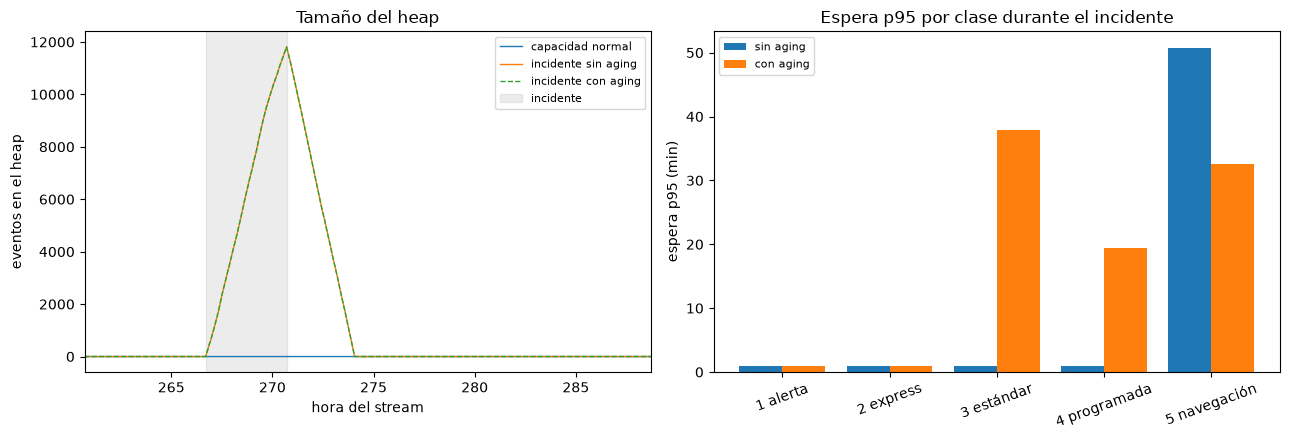

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

horas = lambda serie: np.arange(len(serie)) / 60
ax1.plot(horas(heap_normal), heap_normal, label="capacidad normal", lw=1)
ax1.plot(horas(heap_sin), heap_sin, label="incidente sin aging", lw=1)
ax1.plot(horas(heap_con), heap_con, label="incidente con aging", lw=1, ls="--")
ax1.axvspan(INCIDENTE.start / 60, INCIDENTE.stop / 60, color="gray", alpha=0.15, label="incidente")
ax1.set_xlim(INCIDENTE.start / 60 - 6, INCIDENTE.stop / 60 + 18)
ax1.set_xlabel("hora del stream"); ax1.set_ylabel("eventos en el heap")
ax1.set_title("Tamaño del heap"); ax1.legend(fontsize=8)

clases = sorted(atendidos_con["clase"].unique())
x = np.arange(len(clases))
p95_sin = [atendidos_sin.query("clase == @c")["espera_s"].quantile(0.95) / 60 for c in clases]
p95_con = [atendidos_con.query("clase == @c")["espera_s"].quantile(0.95) / 60 for c in clases]
ax2.bar(x - 0.2, p95_sin, width=0.4, label="sin aging")
ax2.bar(x + 0.2, p95_con, width=0.4, label="con aging")
ax2.set_xticks(x, [NOMBRE_CLASE[c] for c in clases], rotation=20)
ax2.set_ylabel("espera p95 (min)"); ax2.set_title("Espera p95 por clase durante el incidente")
ax2.legend(fontsize=8)

plt.tight_layout()
fig.savefig(CARPETA_RESULTADOS / f"etapa2_aging_{CATEGORIA}.png", dpi=150)
plt.show()

### Espera de la navegación a lo largo del tiempo

La gráfica siguiente muestra la espera de cada evento de navegación en el orden en que fue atendido. Permite ver cuándo se atienden los eventos acumulados durante el incidente.

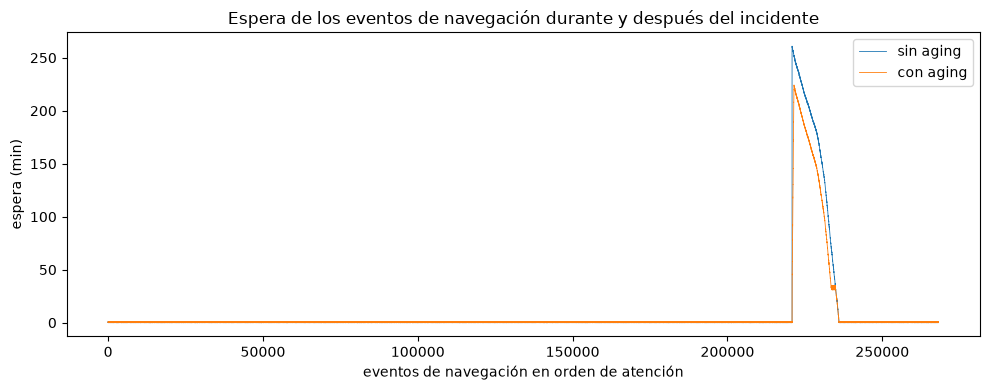

In [9]:
fig, ax = plt.subplots(figsize=(10, 4))
for nombre, atendidos in [("sin aging", atendidos_sin), ("con aging", atendidos_con)]:
    nav = atendidos.query("clase == 5")["espera_s"].reset_index(drop=True) / 60
    ax.plot(nav.index, nav.values, lw=0.6, label=nombre)
ax.set_xlabel("eventos de navegación en orden de atención")
ax.set_ylabel("espera (min)")
ax.set_title("Espera de los eventos de navegación durante y después del incidente")
ax.legend()
plt.tight_layout()
plt.show()

### Lectura de los resultados

Los valores citados corresponden a la ejecución guardada, con eventos de `Office_Products` en modo desarrollo.

- **Capacidad normal.** Todas las clases se atienden en un minuto o menos y al 100 % dentro de plazo, incluidas las alertas con su plazo de 5 minutos. La simulación por minutos permite medir ese plazo.
- **Alertas y compras express durante el incidente.** Con y sin aging se atienden dentro de plazo, con una espera máxima de 1 minuto las alertas y de 1.9 minutos las compras express. Durante el incidente llegan 12.1 eventos urgentes por minuto y solo se atienden 5, pero las alertas y las compras express son pocas y la prioridad por clase las atiende primero.
- **Navegación sin aging.** La espera media es de 9.6 minutos, el p95 de 50.8 y la máxima de 261. Los eventos de navegación acumulados solo salen cuando la capacidad se recupera.
- **Navegación con aging.** La espera media baja a 7.7 minutos (un 20 % menos), el p95 a 32.5 (un 36 % menos) y la máxima a 224. Los eventos que esperan más de 30 minutos suben a la clase 3 y se atienden antes que las compras estándar y programadas.
- **El costo del aging.** Las compras estándar pasan de 3.7 a 11.6 minutos de espera media, con un máximo de 360, y las programadas de 5.7 a 13.0, con un máximo de 418. Las dos siguen al 100 % dentro de plazo, porque sus plazos son de 24 h y 72 h. El aging traslada la espera a las clases que tienen holgura.
- **Lo que el aging no resuelve.** La navegación queda al 94.7 % dentro de su plazo de 30 minutos con y sin aging, y el tamaño del heap es idéntico en los dos escenarios. El heap llega a unos 12 000 eventos y tarda unas 3.5 horas en vaciarse después del incidente. Ninguna política de orden compensa la falta de capacidad; la cola de prioridades decide quién espera, pero no reduce la espera total.

En resumen, la etapa cumple el requisito del escenario B. Las alertas y las órdenes express se atienden primero aun con el sistema saturado, y el aging reduce la espera de la navegación sin poner en riesgo los plazos de ninguna orden.

## Paso 7. Experimentos de complejidad

Se realizan dos experimentos.

| Experimento | Implementación propia | Líneas base | Complejidad esperada |
| --- | --- | --- | --- |
| A. n push seguidos de n pop | `MinHeap` | `heapq` (en C) y lista ordenada (`bisect.insort` y `pop(0)`) | O(n log n) para los heaps, O(n²) para la lista |
| B. Construcción del heap | `heapify` (Floyd) | n push sucesivos y `heapq.heapify` | O(n) frente a O(n log n) |

Condiciones comunes a los dos experimentos.

- **Elementos.** Tuplas `(clase, deadline, seq)` aleatorias con la semilla 42, que tienen la misma forma que las claves reales.
- **Tamaños.** 1K, 10K, 100K, 1M y 10M.
- **Repeticiones.** 100 para 1K y 10K, 20 para 100K, 5 para 1M y 1 para 10M, por el tiempo que toma cada ejecución en Python.
- **Límite de la lista ordenada.** Se mide solo hasta 100K, con 3 repeticiones en ese tamaño, porque cada inserción y cada `pop(0)` desplazan O(n) elementos.
- **Recolector de basura.** Desactivado durante cada medición.
- **Resultados.** Se guardan en CSV dentro de `results/`. Para medir de nuevo se cambia `REEJECUTAR_EXPERIMENTOS` a `True`.

In [10]:
REEJECUTAR_EXPERIMENTOS = False
TAMANOS = [1_000, 10_000, 100_000, 1_000_000, 10_000_000]
REPETICIONES = {1_000: 100, 10_000: 100, 100_000: 20, 1_000_000: 5, 10_000_000: 1}
LIMITE_LISTA = 100_000


def generar_claves(n):
    rng = random.Random(SEED)
    return [(rng.randint(1, 5), rng.random(), i) for i in range(n)]


def medir(funcion, *args):
    gc.collect()
    gc.disable()
    try:
        t0 = time.perf_counter()
        funcion(*args)
        return time.perf_counter() - t0
    finally:
        gc.enable()


def ejecutar_experimento(nombre_csv, metodos, repeticiones_para, generar=generar_claves):
    ruta = CARPETA_RESULTADOS / nombre_csv
    if ruta.exists() and not REEJECUTAR_EXPERIMENTOS:
        print(f"Resultados leídos de {ruta.relative_to(RAIZ)}")
        return pd.read_csv(ruta)
    filas = []
    for n in TAMANOS:
        claves = generar(n)
        for nombre, (funcion, limite_n) in metodos.items():
            if limite_n is not None and n > limite_n:
                continue
            for rep in range(repeticiones_para(nombre, n)):
                filas.append({"metodo": nombre, "n": n, "repeticion": rep, "segundos": medir(funcion, claves)})
        del claves
        print(f"n = {n:>10,} medido")
    resultado = pd.DataFrame(filas)
    resultado.to_csv(ruta, index=False)
    print(f"Resultados guardados en {ruta.relative_to(RAIZ)}")
    return resultado


def resumir(tiempos):
    return (tiempos.groupby(["metodo", "n"])["segundos"]
            .agg(promedio_s="mean", desv_est_s="std", repeticiones="count").reset_index())


def pendientes(resumen, esperado):
    filas = []
    for nombre, datos in resumen.groupby("metodo"):
        k, _ = np.polyfit(np.log10(datos["n"]), np.log10(datos["promedio_s"]), 1)
        filas.append({"metodo": nombre, "pendiente_empirica": round(k, 2), "esperado": esperado[nombre],
                      "rango_n": f"{datos['n'].min():,} a {datos['n'].max():,}"})
    return pd.DataFrame(filas)

### Experimento A. Insertar y extraer

Cada medición inserta n claves y luego extrae las n en orden. Para los heaps se espera O(n log n), es decir, una pendiente log-log entre 1.0 y 1.1. Para la lista ordenada se espera O(n²), con pendiente cercana a 2.

Resultados leídos de results\etapa2_push_pop_tiempos.csv


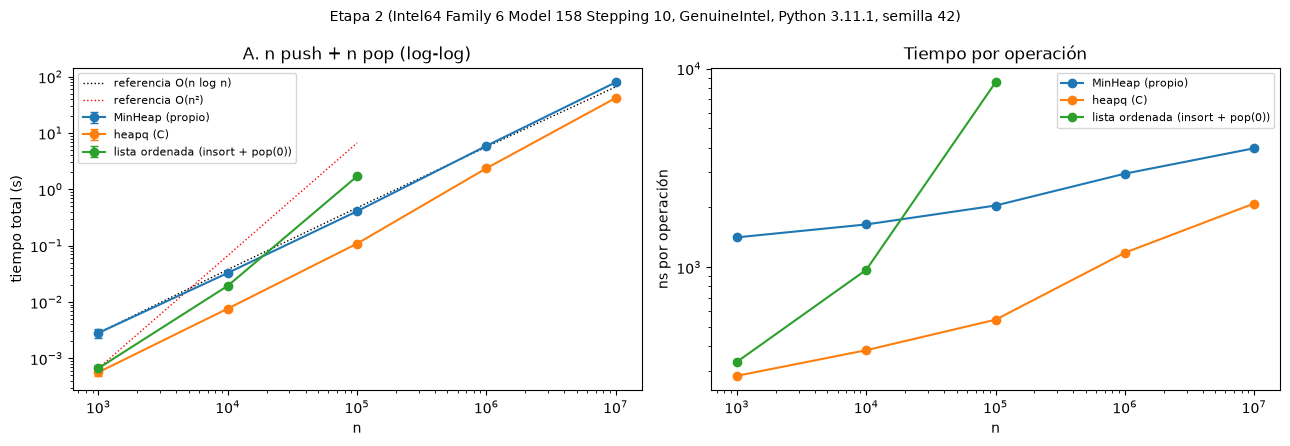

,metodo,n,promedio_s,desv_est_s,repeticiones,ns_por_operacion
0,MinHeap (propio),1000,0.002828,0.000558,100,1413.969000
1,MinHeap (propio),10000,0.032843,0.001274,100,1642.132400
2,MinHeap (propio),100000,0.408957,0.008021,20,2044.786175
3,MinHeap (propio),1000000,5.917769,0.134191,5,2958.884730
4,MinHeap (propio),10000000,79.462438,NaN,1,3973.121900
5,heapq (C),1000,0.000568,0.000078,100,283.812000
6,heapq (C),10000,0.007641,0.000314,100,382.032450
7,heapq (C),100000,0.108820,0.002270,20,544.100575
8,heapq (C),1000000,2.365700,0.078613,5,1182.850180
9,heapq (C),10000000,41.864489,NaN,1,2093.224445


,metodo,pendiente_empirica,esperado,rango_n
0,MinHeap (propio),1.12,≈1.0-1.1 (n log n),"1,000 a 10,000,000"
1,heapq (C),1.22,≈1.0-1.1 (n log n),"1,000 a 10,000,000"
2,lista ordenada (insort + pop(0)),1.70,≈2 (n²),"1,000 a 100,000"


In [11]:
def push_pop_propio(claves):
    h = MinHeap()
    for k in claves:
        h.push(k)
    while len(h):
        h.pop()

def push_pop_heapq(claves):
    h = []
    for k in claves:
        heapq.heappush(h, k)
    while h:
        heapq.heappop(h)

def push_pop_lista_ordenada(claves):
    lista = []
    for k in claves:
        bisect.insort(lista, k)          # O(n): desplaza los elementos mayores
    while lista:
        lista.pop(0)                     # O(n): desplaza todos los demás

tiempos_a = ejecutar_experimento(
    "etapa2_push_pop_tiempos.csv",
    {"MinHeap (propio)": (push_pop_propio, None),
     "heapq (C)": (push_pop_heapq, None),
     "lista ordenada (insort + pop(0))": (push_pop_lista_ordenada, LIMITE_LISTA)},
    lambda nombre, n: min(REPETICIONES[n], 3) if nombre.startswith("lista") and n >= LIMITE_LISTA else REPETICIONES[n])
resumen_a = resumir(tiempos_a)
resumen_a["ns_por_operacion"] = resumen_a["promedio_s"] / (2 * resumen_a["n"]) * 1e9

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
for nombre, datos in resumen_a.groupby("metodo"):
    ax1.errorbar(datos["n"], datos["promedio_s"], yerr=datos["desv_est_s"], marker="o", capsize=3, label=nombre)
    ax2.plot(datos["n"], datos["ns_por_operacion"], marker="o", label=nombre)
n_ref = np.array(TAMANOS, dtype=float)
base = resumen_a.query("metodo == 'MinHeap (propio)'").iloc[0]
ax1.plot(n_ref, base["promedio_s"] * (n_ref * np.log2(n_ref)) / (base["n"] * np.log2(base["n"])),
         "k:", lw=1, label="referencia O(n log n)")
base_l = resumen_a[resumen_a["metodo"].str.startswith("lista")].iloc[0]
n_l = n_ref[n_ref <= LIMITE_LISTA]
ax1.plot(n_l, base_l["promedio_s"] * (n_l / base_l["n"]) ** 2, "r:", lw=1, label="referencia O(n²)")
for ax, titulo, ylabel in [(ax1, "A. n push + n pop (log-log)", "tiempo total (s)"),
                           (ax2, "Tiempo por operación", "ns por operación")]:
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("n"); ax.set_ylabel(ylabel); ax.set_title(titulo); ax.legend(fontsize=8)
plt.suptitle(f"Etapa 2 ({PLATAFORMA['procesador']}, Python {PLATAFORMA['python']}, semilla {SEED})", fontsize=10)
plt.tight_layout()
fig.savefig(CARPETA_RESULTADOS / "etapa2_push_pop.png", dpi=150)
plt.show()

display(resumen_a)
pendientes(resumen_a, {"MinHeap (propio)": "≈1.0-1.1 (n log n)", "heapq (C)": "≈1.0-1.1 (n log n)",
                       "lista ordenada (insort + pop(0))": "≈2 (n²)"})

### Experimento B. Construcción del heap

Se construye un heap con n claves de dos formas. La primera inserta las claves una por una con `push` y la segunda aplica `heapify` de Floyd sobre el arreglo completo.

La comparación se hace con dos órdenes de entrada, porque el costo de `push` depende de los datos.

- **Claves aleatorias (caso promedio).** Un elemento nuevo sube en promedio menos de dos niveles, porque la mitad de los nodos de un heap son hojas y la mayoría de los elementos ya es mayor que su padre. Por eso n `push` con datos aleatorios cuestan O(n) en promedio, aunque su cota sea O(n log n).
- **Claves en orden decreciente (peor caso).** Cada clave nueva es menor que todas las anteriores y sube hasta la raíz, recorriendo ⌊log₂ k⌋ niveles. El costo total es Θ(n log n).

`heapify` cuesta O(n) en los dos casos. Si es lineal, su tiempo por elemento se mantiene constante al crecer n, mientras que el de los `push` en el peor caso crece con log n. Esta garantía justifica usar `heapify` en las pasadas de aging, donde las claves cambian de forma arbitraria.

Resultados leídos de results\etapa2_heapify_tiempos.csv


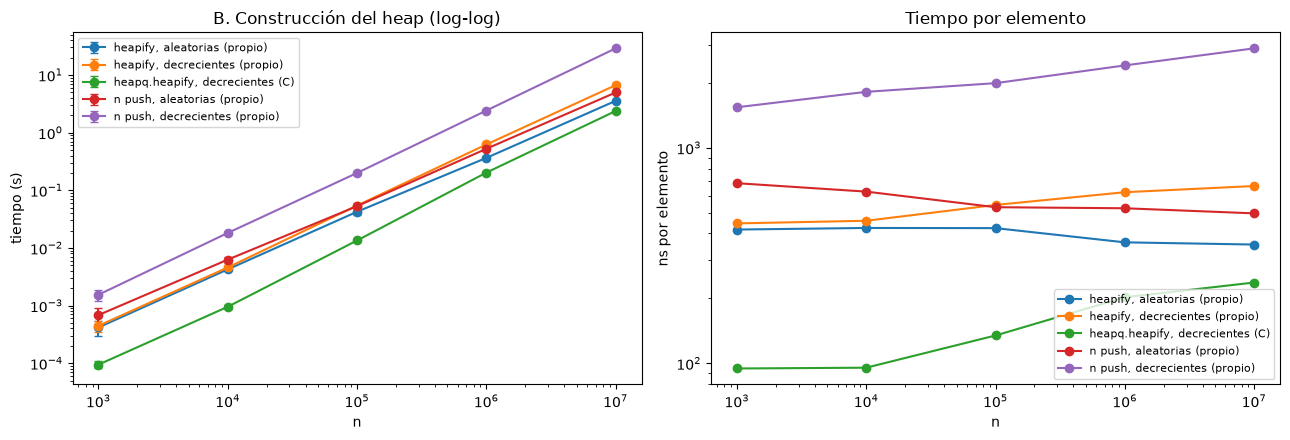

,metodo,n,promedio_s,desv_est_s,repeticiones,ns_por_elemento
0,"heapify, aleatorias (propio)",1000,0.000417,0.000120,100,417.12300
1,"heapify, aleatorias (propio)",10000,0.004243,0.000280,100,424.30980
2,"heapify, aleatorias (propio)",100000,0.042354,0.005578,20,423.53650
3,"heapify, aleatorias (propio)",1000000,0.363856,0.006237,5,363.85626
4,"heapify, aleatorias (propio)",10000000,3.553714,NaN,1,355.37141
5,"heapify, decrecientes (propio)",1000,0.000446,0.000101,100,445.51500
6,"heapify, decrecientes (propio)",10000,0.004582,0.000285,100,458.22800
7,"heapify, decrecientes (propio)",100000,0.054261,0.005030,20,542.61420
8,"heapify, decrecientes (propio)",1000000,0.621730,0.005647,5,621.72960
9,"heapify, decrecientes (propio)",10000000,6.642079,NaN,1,664.20793


,metodo,pendiente_empirica,esperado,rango_n
0,"heapify, aleatorias (propio)",0.98,≈1 (n),"1,000 a 10,000,000"
1,"heapify, decrecientes (propio)",1.05,≈1 (n),"1,000 a 10,000,000"
2,"heapq.heapify, decrecientes (C)",1.11,≈1 (n),"1,000 a 10,000,000"
3,"n push, aleatorias (propio)",0.96,"≈1 (n, caso promedio)","1,000 a 10,000,000"
4,"n push, decrecientes (propio)",1.07,"≈1.0-1.1 (n log n, peor caso)","1,000 a 10,000,000"


In [12]:
def generar_claves_dos_ordenes(n):
    claves = generar_claves(n)
    return claves, sorted(claves, reverse=True)      # (aleatorias, decrecientes)

def push_aleatorias(datos):
    h = MinHeap()
    for k in datos[0]:
        h.push(k)

def push_decrecientes(datos):
    h = MinHeap()
    for k in datos[1]:
        h.push(k)

def heapify_aleatorias(datos):
    MinHeap(datos[0])

def heapify_decrecientes(datos):
    MinHeap(datos[1])

def heapq_heapify_decrecientes(datos):
    heapq.heapify(list(datos[1]))

tiempos_b = ejecutar_experimento(
    "etapa2_heapify_tiempos.csv",
    {"n push, aleatorias (propio)": (push_aleatorias, None),
     "n push, decrecientes (propio)": (push_decrecientes, None),
     "heapify, aleatorias (propio)": (heapify_aleatorias, None),
     "heapify, decrecientes (propio)": (heapify_decrecientes, None),
     "heapq.heapify, decrecientes (C)": (heapq_heapify_decrecientes, None)},
    lambda nombre, n: REPETICIONES[n],
    generar=generar_claves_dos_ordenes)
resumen_b = resumir(tiempos_b)
resumen_b["ns_por_elemento"] = resumen_b["promedio_s"] / resumen_b["n"] * 1e9

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
for nombre, datos in resumen_b.groupby("metodo"):
    ax1.errorbar(datos["n"], datos["promedio_s"], yerr=datos["desv_est_s"], marker="o", capsize=3, label=nombre)
    ax2.plot(datos["n"], datos["ns_por_elemento"], marker="o", label=nombre)
for ax, titulo, ylabel in [(ax1, "B. Construcción del heap (log-log)", "tiempo (s)"),
                           (ax2, "Tiempo por elemento", "ns por elemento")]:
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("n"); ax.set_ylabel(ylabel); ax.set_title(titulo); ax.legend(fontsize=8)
plt.tight_layout()
fig.savefig(CARPETA_RESULTADOS / "etapa2_heapify.png", dpi=150)
plt.show()

display(resumen_b)
pendientes(resumen_b, {"n push, aleatorias (propio)": "≈1 (n, caso promedio)",
                       "n push, decrecientes (propio)": "≈1.0-1.1 (n log n, peor caso)",
                       "heapify, aleatorias (propio)": "≈1 (n)",
                       "heapify, decrecientes (propio)": "≈1 (n)",
                       "heapq.heapify, decrecientes (C)": "≈1 (n)"})

### Memoria

Se mide con `tracemalloc` la memoria pico de insertar n claves y extraerlas, hasta 1M. Las claves se generan antes de la medición, así que la cifra corresponde solo a la estructura. Se espera que todas usen unos 8 bytes por elemento, porque las tres guardan una referencia por elemento en un arreglo.

In [13]:
ruta_memoria = CARPETA_RESULTADOS / "etapa2_memoria.csv"
if ruta_memoria.exists() and not REEJECUTAR_EXPERIMENTOS:
    memoria = pd.read_csv(ruta_memoria)
else:
    filas = []
    for n in [1_000, 10_000, 100_000, 1_000_000]:
        claves = generar_claves(n)
        for nombre, funcion in [("MinHeap (propio)", push_pop_propio), ("heapq (C)", push_pop_heapq),
                                ("lista ordenada (insort + pop(0))", push_pop_lista_ordenada)]:
            if nombre.startswith("lista") and n > LIMITE_LISTA:
                continue
            gc.collect()
            tracemalloc.start()
            funcion(claves)
            _, pico = tracemalloc.get_traced_memory()
            tracemalloc.stop()
            filas.append({"metodo": nombre, "n": n, "pico_mb": pico / 1e6})
    memoria = pd.DataFrame(filas)
    memoria.to_csv(ruta_memoria, index=False)

memoria["bytes_por_elemento"] = memoria["pico_mb"] * 1e6 / memoria["n"]
memoria.pivot(index="n", columns="metodo", values="bytes_por_elemento").round(1)

metodo,MinHeap (propio),heapq (C),lista ordenada (insort + pop(0))
n,,,
1000,9.1,8.9,8.9
10000,8.5,8.5,8.5
100000,8.0,8.0,8.0
1000000,8.5,8.5,NaN


### Lectura de los resultados

Los valores citados corresponden a la ejecución guardada en `results/`. Al medir de nuevo pueden variar ligeramente.

- **Experimento A, heaps.** `MinHeap` tiene una pendiente de 1.12, coherente con O(n log n). Su tiempo por operación pasa de unos 1 400 ns a 1K a unos 4 000 ns a 10M. Ese aumento de unas 2.8 veces es algo mayor que el de log₂ n, que pasa de 10 a 23 (2.3 veces). La diferencia se debe a la memoria. Con millones de tuplas dispersas en la RAM, muchas comparaciones esperan datos que no están en la caché del procesador.
- **Experimento A, `heapq`.** Es unas 5 veces más rápido que `MinHeap` a 1K, porque está escrito en C, pero solo unas 2 veces más rápido a 10M. Su pendiente (1.22) es mayor que la del heap propio porque su costo por operación es tan bajo que el acceso a memoria pasa a dominar. Con n grande, el límite lo pone la jerarquía de memoria y no el lenguaje.
- **Experimento A, lista ordenada.** Su pendiente es 1.70 y su tiempo por operación crece unas 25 veces de 1K a 100K, de 330 a 8 500 ns. Esto confirma el costo O(n) de cada operación. La pendiente es menor que 2 porque el desplazamiento de elementos lo hace `memmove` en C, que es muy rápido con n pequeño. A 100K ya es 4 veces más lenta que `MinHeap` y la diferencia crece con n.
- **Experimento B.** Con claves aleatorias, n `push` y `heapify` son lineales (pendientes 0.96 y 0.98), como predice el análisis del caso promedio. Con claves decrecientes, el tiempo por elemento de los `push` crece de unos 1 540 a 2 890 ns, mientras que el de `heapify` crece de 450 a 660 ns. A 10M construir con `push` cuesta 4.4 veces más que con `heapify`. `heapify` también crece un poco por elemento, igual que `heapq.heapify` en C, por el efecto de la caché en arreglos grandes, aunque su número de operaciones es O(n).
- **Memoria.** Las tres estructuras usan unos 8 bytes por elemento, una referencia por posición del arreglo. El heap no tiene costo de memoria adicional frente a una lista.

El heap propio cumple las complejidades teóricas. Se mantiene en la etapa 2 porque la cola de prioridades es una estructura evaluada del proyecto y porque el aging necesita acceder al arreglo interno para recalcular las claves y aplicar `heapify`. `heapq` queda como referencia de lo que se ganaría con una implementación en C.

## Paso 8. Salida de la etapa 2

La salida son los eventos **en el orden en que la etapa 2 los atiende**, con los campos `priority` y `deadline` ya asignados. Se guarda la ejecución del escenario de incidente con aging, que es la configuración adoptada. Cada línea del archivo es un ciclo de servicio.

Las etapas siguientes usan esta salida de distintas formas.

| Etapa | Uso |
| --- | --- |
| 3. Hash, LRU | Actualiza la caché de productos y usuarios en el orden de servicio |
| 6. Bloom Filter y Count-Min Sketch | Revisa `payment_id`, `device_id` y `user_id` contra las listas de señalados y cuenta intentos por ventana |
| 8. Grafo de co-compra | Agrupa las compras por `order_id` para crear las aristas entre productos |

El archivo es `data/interim/<CATEGORIA>/etapa2_eventos.jsonl`.

In [14]:
ruta_salida = CARPETA_INTERIM / "etapa2_eventos.jsonl"
with open(ruta_salida, "w", encoding="utf-8") as archivo:
    for ciclo, eventos in orden_servicio:
        if eventos:
            archivo.write(json.dumps({"ciclo": ciclo, "eventos": [asdict(e) for e in eventos]}) + "\n")

total = 0
with open(ruta_salida, encoding="utf-8") as archivo:
    for linea in archivo:
        total += len(json.loads(linea)["eventos"])
assert total == n_eventos, "la etapa 2 debe atender todos los eventos"
print(f"{ruta_salida.relative_to(RAIZ)}: {total:,} eventos en {len(orden_servicio)} ciclos "
      f"({ruta_salida.stat().st_size / 1e6:.1f} MB)")

# Primeros eventos atendidos en el primer ciclo del incidente
primer_ciclo_incidente = dict(orden_servicio)[INCIDENTE.start]
pd.DataFrame([{"event_type": e.event_type, "order_type": e.order_type, "priority": e.priority,
               "order_id": e.order_id, "payment_id": e.payment_id}
              for e in primer_ciclo_incidente[:12]])

data\interim\Office_Products\etapa2_eventos.jsonl: 343,887 eventos en 18641 ciclos (123.9 MB)


,event_type,order_type,priority,order_id,payment_id
0,purchase,standard,3,o00040270,pay_425e170a
1,return,standard,3,o00040142,pay_b11e734c
2,purchase,standard,3,o00040271,pay_db10bbf8
3,purchase,scheduled,4,o00040265,pay_4709299d
4,purchase,scheduled,4,o00040273,pay_07b5ceaf


### Datos para las etapas 6 y 8

Se muestran dos ejemplos de cómo las etapas siguientes pueden usar la salida.

- **Etapa 6.** Las alertas de pago salen primero en su ciclo. Se cuenta cuántas alertas tienen una tarjeta de la lista de señalados que generó la etapa 0. Las alertas que no están en la lista son las falsas alarmas que la etapa 6 debe verificar antes de bloquear.
- **Etapa 8.** Se cuentan las órdenes con más de un producto, que son las que crean aristas en el grafo de co-compra.

In [15]:
senalados = json.loads((CARPETA_INTERIM / "listas_senalados.json").read_text(encoding="utf-8"))
tarjetas_senaladas = set(senalados["tarjetas"])     # set solo para este conteo de verificación

alertas = [e for _, lote in orden_servicio for e in lote if e.event_type == "payment_alert"]
con_tarjeta_senalada = sum(e.payment_id in tarjetas_senaladas for e in alertas)
print(f"Alertas de pago atendidas: {len(alertas)}")
print(f"  con tarjeta señalada: {con_tarjeta_senalada}   sin tarjeta señalada (falsas alarmas): "
      f"{len(alertas) - con_tarjeta_senalada}")

productos_por_orden = Counter(e.order_id for _, lote in orden_servicio for e in lote if e.event_type == "purchase")
multiproducto = sum(1 for n in productos_por_orden.values() if n > 1)
print(f"\nÓrdenes de compra: {len(productos_por_orden):,}   con más de un producto: {multiproducto:,}")

Alertas de pago atendidas: 518
  con tarjeta señalada: 371   sin tarjeta señalada (falsas alarmas): 147

Órdenes de compra: 48,639   con más de un producto: 11,824


## Resumen de la etapa 2

| Aspecto | Decisión |
| --- | --- |
| Estructura | Min-heap binario propio sobre un arreglo; push y pop en O(log n), heapify en O(n) |
| Clave | `(clase, deadline, seq)`: clase de urgencia, después el deadline más cercano, después el orden de llegada |
| Clases | 1 alerta de pago, 2 express, 3 estándar y devoluciones, 4 programada, 5 navegación |
| Aging | Sube una clase cada 15 min de espera, sin pasar de la clase 3; pasada cada 5 lotes con heapify en O(n) |
| Salida | Eventos en orden de servicio con `priority` y `deadline`, en `data/interim/<CATEGORIA>/etapa2_eventos.jsonl` |

Referencias. Cormen, T. H., Leiserson, C. E., Rivest, R. L., y Stein, C. (2022). *Introduction to Algorithms* (4.ª ed.), cap. 6. Williams, J. W. J. (1964). Algorithm 232: Heapsort. *Communications of the ACM*, 7(6), 347-348. Floyd, R. W. (1964). Algorithm 245: Treesort 3. *Communications of the ACM*, 7(12), 701.